# FDG PET SUVR ANCOVA: CEUNIM vs Controls


In [8]:
from pathlib import Path
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid", context="talk")


In [9]:
# Paths
merged_summary_csv_path = '../../../../data/processed_pet/merged_summary_csv/'
filename_suvr_mean_harmonized = os.path.join(merged_summary_csv_path, 'summary_suvr_mean_harmonized.csv')
scan_csv_path = os.path.join("../../../../data/pet/", 'pet_scans_info_covid_controls_ceunim_merged.csv')
output_path = '../../../../results/pet/paper_analysis/ancova_rois_mean/'
os.makedirs(output_path, exist_ok=True)
plots_dir = os.path.join(output_path, "ancova_significant_rois")
os.makedirs(plots_dir, exist_ok=True)

Loaded scan information: ../../../../data/pet/pet_scans_info_covid_controls_ceunim_merged.csv
Shape: (55, 18)
Shape after merging with scan information: (54, 116)
Saved merged CSV to: ../../../../results/pet/paper_analysis/ancova_rois_mean/merged_summary_with_scan_info.csv
Unmatched subject IDs: ['CP0106']


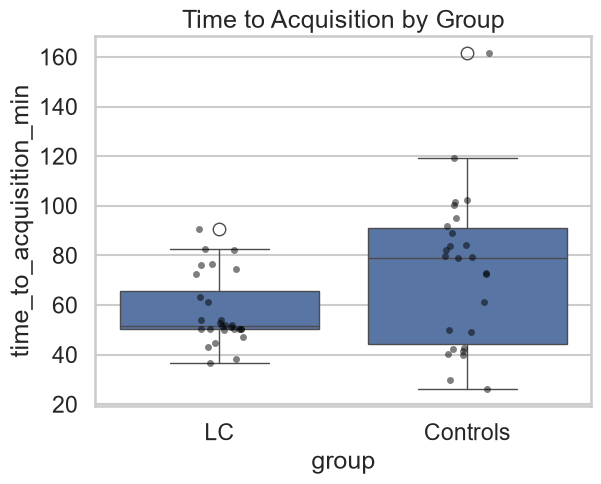

In [10]:
# Load daata from the merged CSV file
df = pd.read_csv(filename_suvr_mean_harmonized)
# Load scan information from the CSV file
scan_df = pd.read_csv(scan_csv_path)
print(f"Loaded scan information: {scan_csv_path}")
print(f"Shape: {scan_df.shape}")
scan_df.head()

# Match using subject_id from scan_df with ID from df
# if columns on both sides have the same name, keep only scan_df columns
df = df.merge(scan_df, left_on="ID", right_on="subject_id", how="inner", suffixes=('', '_y'))
print(f"Shape after merging with scan information: {df.shape}")
df.head()

# save the csv
merged_csv_path = os.path.join(output_path, 'merged_summary_with_scan_info.csv')
df.to_csv(merged_csv_path, index=False)
print(f"Saved merged CSV to: {merged_csv_path}")

# print IDs of unmatched subjects
unmatched_ids = scan_df.loc[~scan_df['subject_id'].isin(df['ID']), 'subject_id']
print(f"Unmatched subject IDs: {unmatched_ids.tolist()}")

# now do a boxplot of compare_df["time_to_injection_min"]
sns.boxplot(x="group", y="time_to_acquisition_min", data=df)
# add the scatter
sns.stripplot(x="group", y="time_to_acquisition_min", data=df, color="black", alpha=0.5)
plt.title("Time to Acquisition by Group")
plt.show()

In [ ]:
# CEUNIM LC vs CEUNIM Control
compare_df = df.loc[
    (df["site"].eq("CEUNIM")) & (df["group"].isin(["Controls", "LC"]))
].copy()

compare_df["sex"] = compare_df["sex"].astype("category")
compare_df["age"] = pd.to_numeric(compare_df["age"], errors="coerce")
compare_df["time_to_acquisition_min"] = pd.to_numeric(compare_df["time_to_acquisition_min"], errors="coerce")

excluded = {"ID", "group", "site", "sex", "age", "weight", "analysis_group",
            "subject_id", "group_y", "site_y", "age_years", "sex_y", "height_m", "weight_kg", "injected_activity_MBq", "injected_activity_mCi", "glucose_mgdl", "glucose_note", "injection_time", "acquisition_time", "scan_date", "time_to_acquisition_min", "clinical_indication", "decay_correction_method"
}
candidate_roi_cols = [c for c in compare_df.columns if c not in excluded]

roi_cols = []
for col in candidate_roi_cols:
    converted = pd.to_numeric(compare_df[col], errors="coerce")
    if converted.notna().sum() > 0:
        compare_df[col] = converted
        roi_cols.append(col)

print("N CEUNIM subjects for ANCOVA:")
print(compare_df["group"].value_counts(dropna=False))
print(f"Detected ROI SUVR columns: {len(roi_cols)}")

records = []

for roi in roi_cols:
    sub = compare_df[["group", "sex", "age", roi]].dropna().copy()

    if sub["group"].nunique() < 2:
        continue
    if sub["sex"].nunique() < 2:
        continue

    formula = f'Q("{roi}") ~ C(group) + C(sex) + age'
    model = ols(formula, data=sub).fit()
    anova_tbl = sm.stats.anova_lm(model, typ=2)

    group_term = "C(group)"
    if group_term not in anova_tbl.index:
        continue

    mean_control = sub.loc[sub["group"].eq("Controls"), roi].mean()
    mean_lc = sub.loc[sub["group"].eq("LC"), roi].mean()

    records.append(
        {
            "ROI": roi,
            "n": len(sub),
            "F_group": anova_tbl.loc[group_term, "F"],
            "p_group": anova_tbl.loc[group_term, "PR(>F)"],
            "mean_control": mean_control,
            "mean_lc": mean_lc,
            "delta_lc_minus_control": mean_lc - mean_control, 
            "direction": "hyper" if mean_lc > mean_control else "hypo",
            # p and betas for covariate:
            "p_sex": anova_tbl.loc["C(sex)", "PR(>F)"],
            "beta_sex": model.params.get("C(sex)[T.1]", np.nan),
            "p_age": anova_tbl.loc["age", "PR(>F)"],
            "beta_age": model.params.get("age", np.nan)
        }
    )

results_df = pd.DataFrame(records).sort_values("p_group").reset_index(drop=True)

if len(results_df) > 0:
    rej, p_fdr, _, _ = multipletests(results_df["p_group"], alpha=0.05, method="fdr_bh")
    results_df["p_fdr"] = p_fdr
    results_df["significant_fdr"] = rej
else:
    results_df["p_fdr"] = pd.Series(dtype=float)
    results_df["significant_fdr"] = pd.Series(dtype=bool)

print(results_df.head(20))

output_filename_csv = os.path.join(output_path, "ancova_lc_vs_ceunim_controls_results.csv")
results_df.to_csv(output_filename_csv, index=False)

signif_df = results_df.loc[results_df["significant_fdr"].eq(True)].copy()
signif_df.to_csv(os.path.join(output_path, "ancova_lc_vs_ceunim_controls_significant_results_cerebellum.csv"), index=False)
print(f"Saved full ANCOVA table: {output_filename_csv}")
print(f"Significant ROIs (FDR < 0.05): {len(signif_df)}")

# Now repeat using time to scan acquisition (time_to_acquisition_min)
records_time_to_acquisition = []
for roi in roi_cols:
    sub = compare_df[["group", "sex", "age", "time_to_acquisition_min", roi]].dropna().copy()

    formula = f'Q("{roi}") ~ C(group) + C(sex) + age + time_to_acquisition_min'
    model = ols(formula, data=sub).fit()
    anova_tbl = sm.stats.anova_lm(model, typ=2)

    group_term = "C(group)"

    mean_control = sub.loc[sub["group"].eq("Controls"), roi].mean()
    mean_lc = sub.loc[sub["group"].eq("LC"), roi].mean()

    records_time_to_acquisition.append(
        {
            "ROI": roi,
            "n": len(sub),
            "F_group": anova_tbl.loc[group_term, "F"],
            "p_group": anova_tbl.loc[group_term, "PR(>F)"],
            "beta_group": model.params.get("C(group)[T.LC]", np.nan),
            "mean_control": mean_control,
            "mean_lc": mean_lc,
            "delta_lc_minus_control": mean_lc - mean_control, 
            "direction": "hyper" if mean_lc > mean_control else "hypo",
            # p and betas for covariate:
            "p_sex": anova_tbl.loc["C(sex)", "PR(>F)"],
            "beta_sex": model.params.get("C(sex)[T.1]", np.nan),
            "p_age": anova_tbl.loc["age", "PR(>F)"],
            "beta_age": model.params.get("age", np.nan),
            "p_time_to_acquisition_min": anova_tbl.loc["time_to_acquisition_min", "PR(>F)"],
            "beta_time_to_acquisition_min": model.params.get("time_to_acquisition_min", np.nan),
        }
    )

results_df_time_to_acquisition = pd.DataFrame(records_time_to_acquisition).sort_values("p_group").reset_index(drop=True)

if len(results_df_time_to_acquisition) > 0:
    rej, p_fdr, _, _ = multipletests(results_df_time_to_acquisition["p_group"], alpha=0.05, method="fdr_bh")
    results_df_time_to_acquisition["p_fdr"] = p_fdr
    results_df_time_to_acquisition["significant_fdr"] = rej
else:
    results_df_time_to_acquisition["p_fdr"] = pd.Series(dtype=float)
    results_df_time_to_acquisition["significant_fdr"] = pd.Series(dtype=bool)

print(results_df_time_to_acquisition.head(20))

output_filename_csv_time_to_acquisition = os.path.join(output_path, "ancova_lc_vs_ceunim_controls_results_time_to_acquisition.csv")
results_df_time_to_acquisition.to_csv(output_filename_csv_time_to_acquisition, index=False)

signif_df_time_to_acquisition = results_df_time_to_acquisition.loc[results_df_time_to_acquisition["significant_fdr"].eq(True)].copy()
signif_df_time_to_acquisition.to_csv(os.path.join(output_path, "ancova_lc_vs_ceunim_controls_significant_results_time_to_acquisition.csv"), index=False)
print(f"Saved full ANCOVA table (time to acquisition): {output_filename_csv_time_to_acquisition}")
print(f"Significant ROIs (FDR < 0.05, time to acquisition): {len(signif_df_time_to_acquisition)}")

N CEUNIM subjects for ANCOVA:
group
LC          28
Controls    26
Name: count, dtype: int64
Detected ROI SUVR columns: 92
                                         ROI   n    F_group   p_group  \
0    TL-middle-and-inferior-temporal-gyrus-L  54  23.891942  0.000011   
1                   PL-supramarginal-gyrus-L  54  20.346334  0.000039   
2                 FL-lateral-orbital-gyrus-L  54  17.624242  0.000110   
3                  FL-middle-frontal-gyrus-L  54  15.919548  0.000216   
4                FL-superior-frontal-gyrus-R  54  15.140125  0.000296   
5               TL-posterior-temporal-lobe-L  54  15.088373  0.000302   
6                FL-inferior-frontal-gyrus-L  54  14.905607  0.000325   
7              CG-anterior-cingulate-gyrus-R  54  13.809157  0.000511   
8                FL-superior-frontal-gyrus-L  54   8.975647  0.004249   
9      brainstem-excluding-substantia-nigra-  54   8.687542  0.004858   
10                                pallidum-L  54   8.466338  0.005387   
11

PermissionError: [Errno 13] Permission denied: '../../../../results/pet/paper_analysis/ancova_rois_mean/ancova_lc_vs_ceunim_controls_results_time_to_acquisition.csv'

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


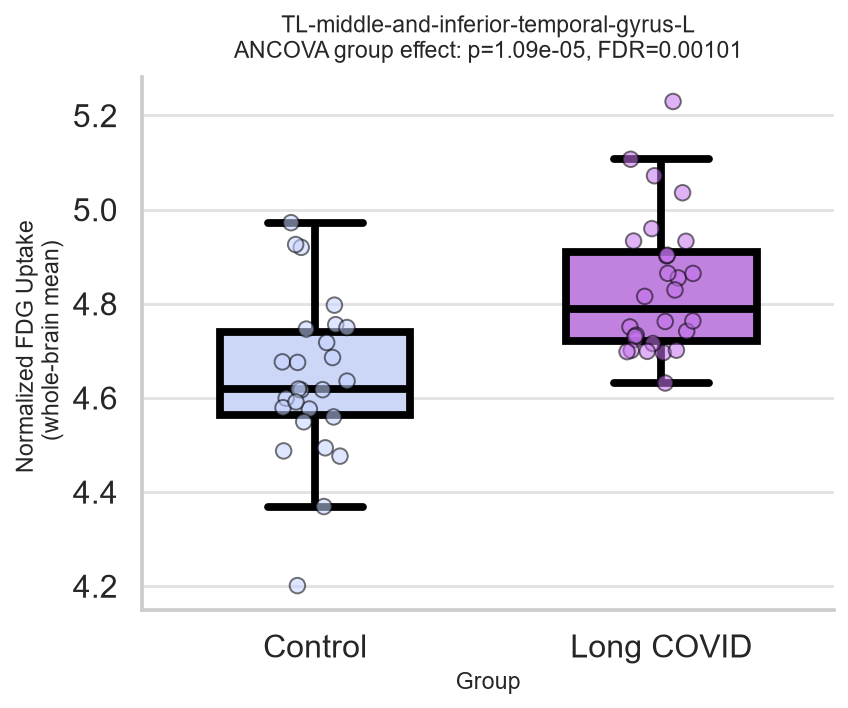

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


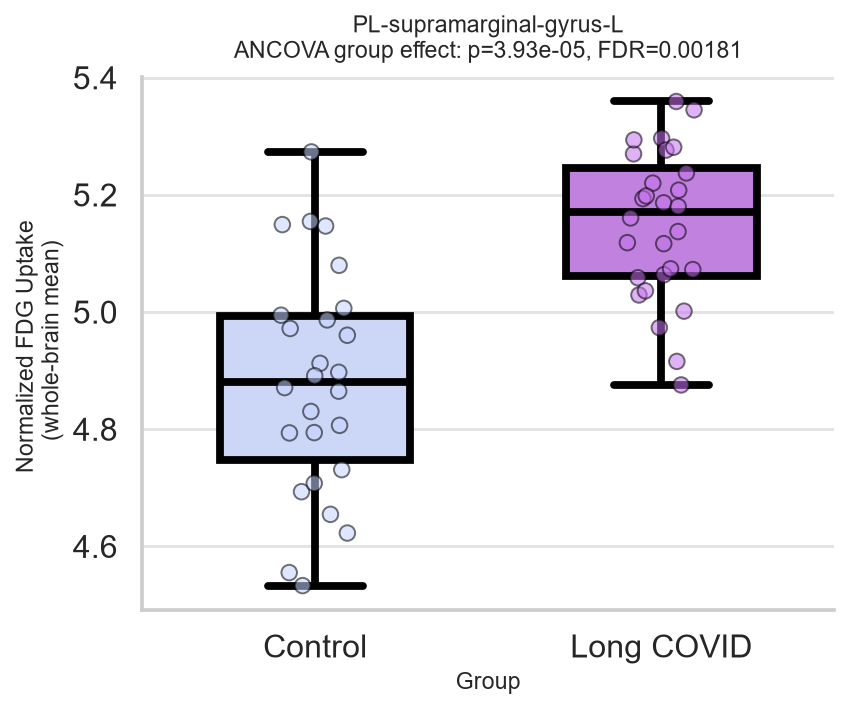

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


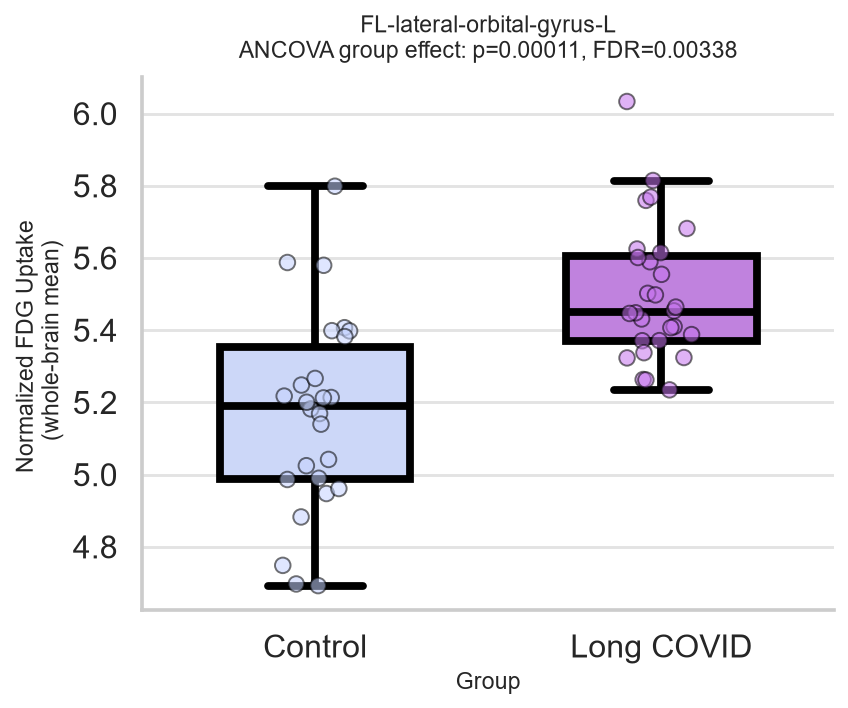

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


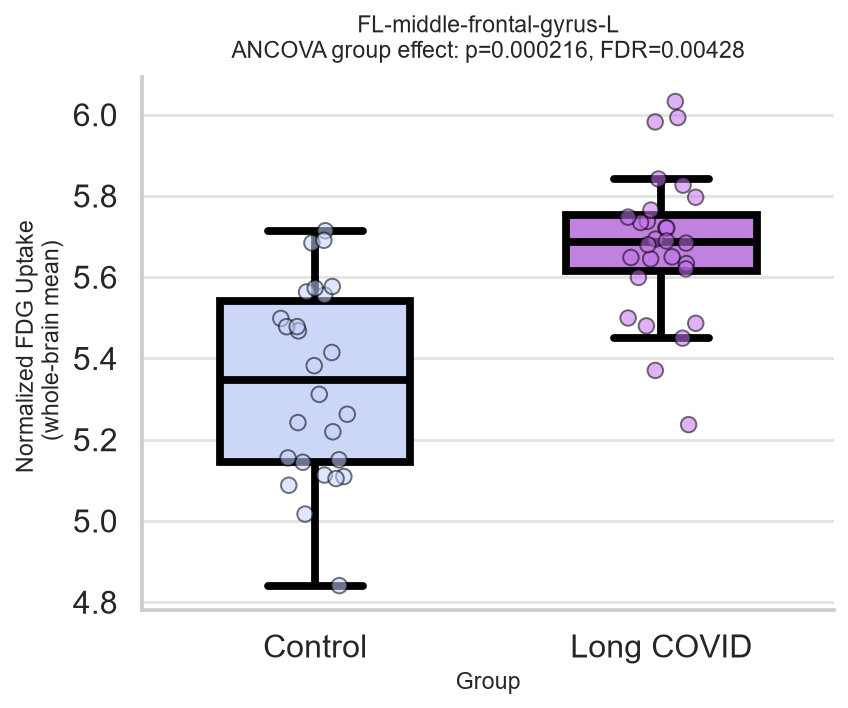

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


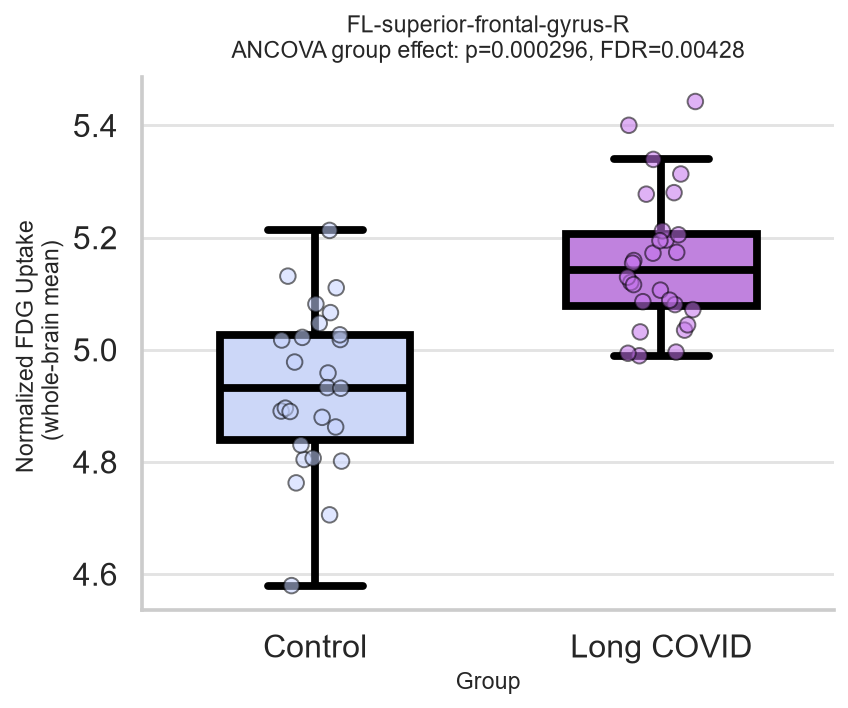

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


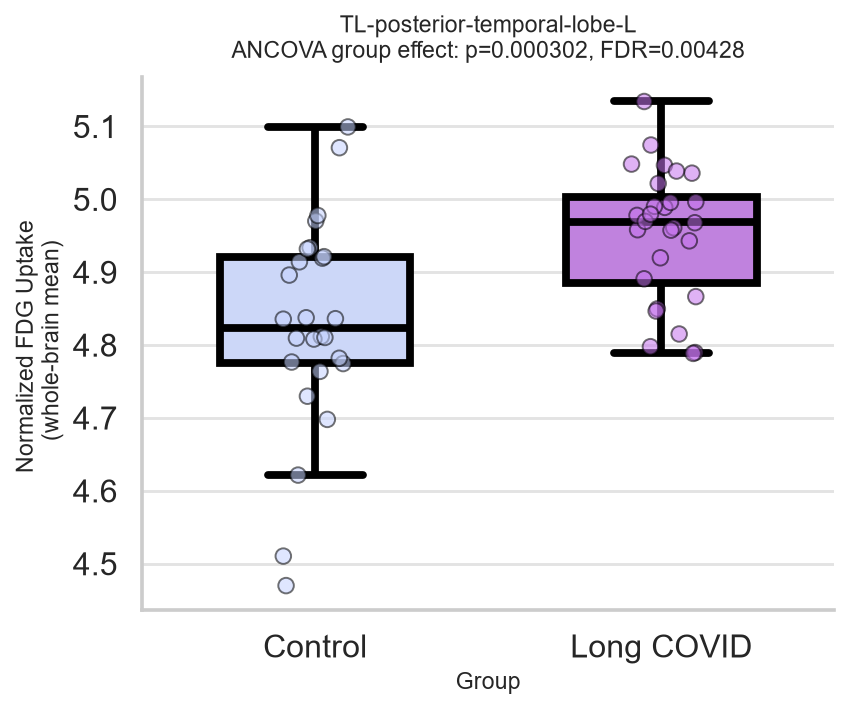

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


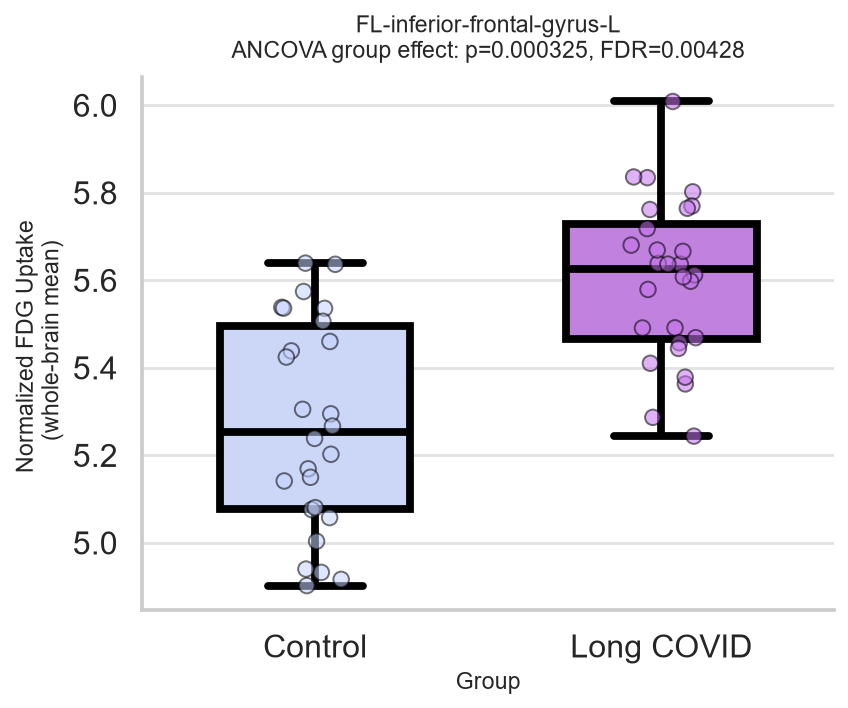

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


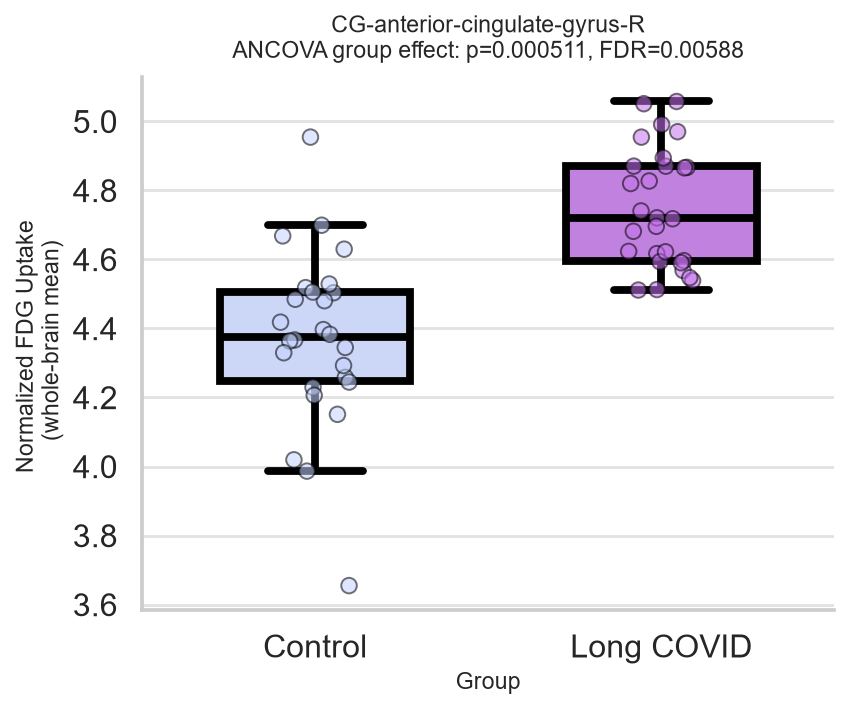

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


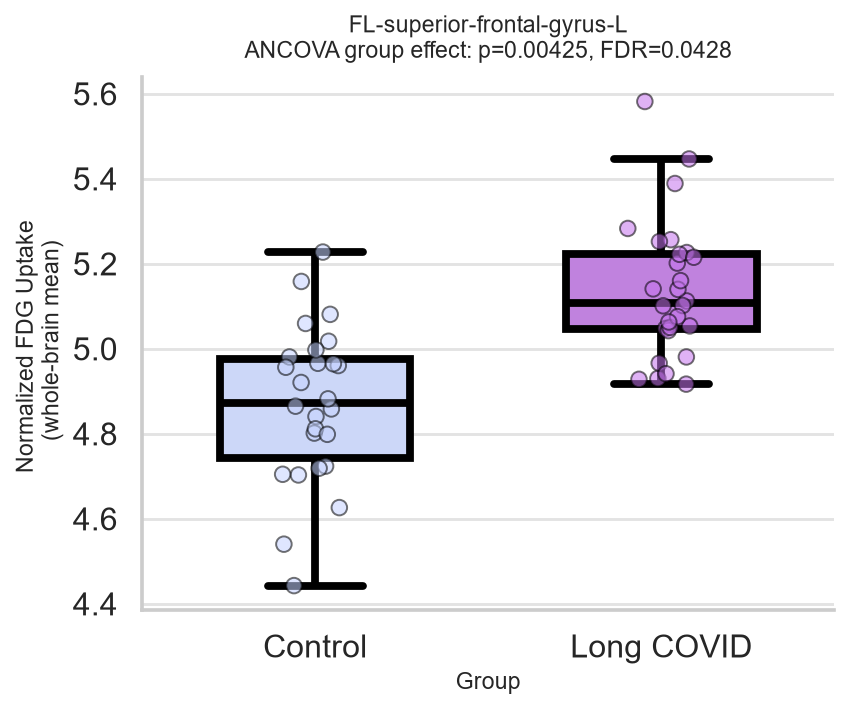

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


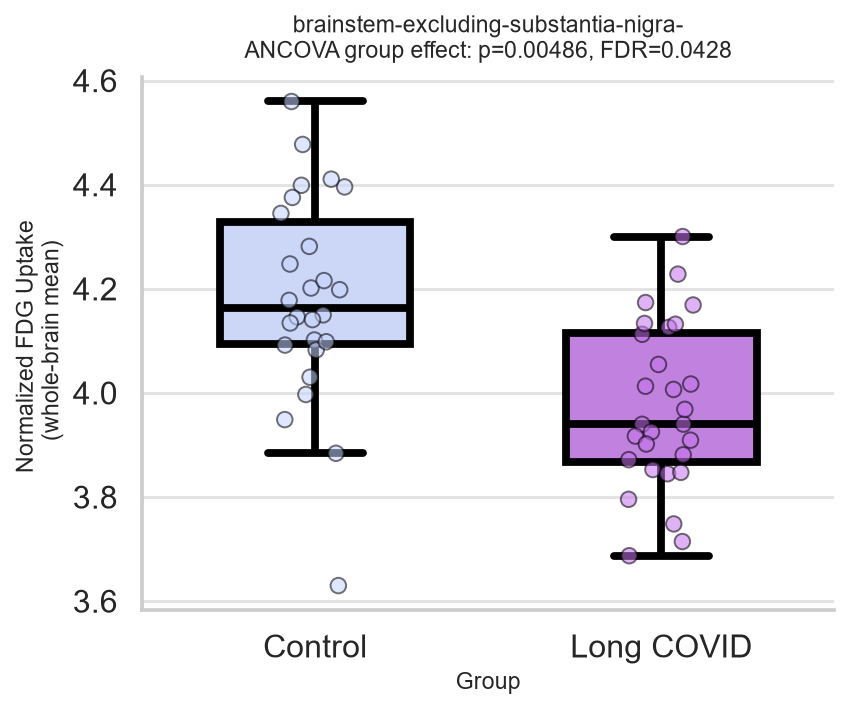

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


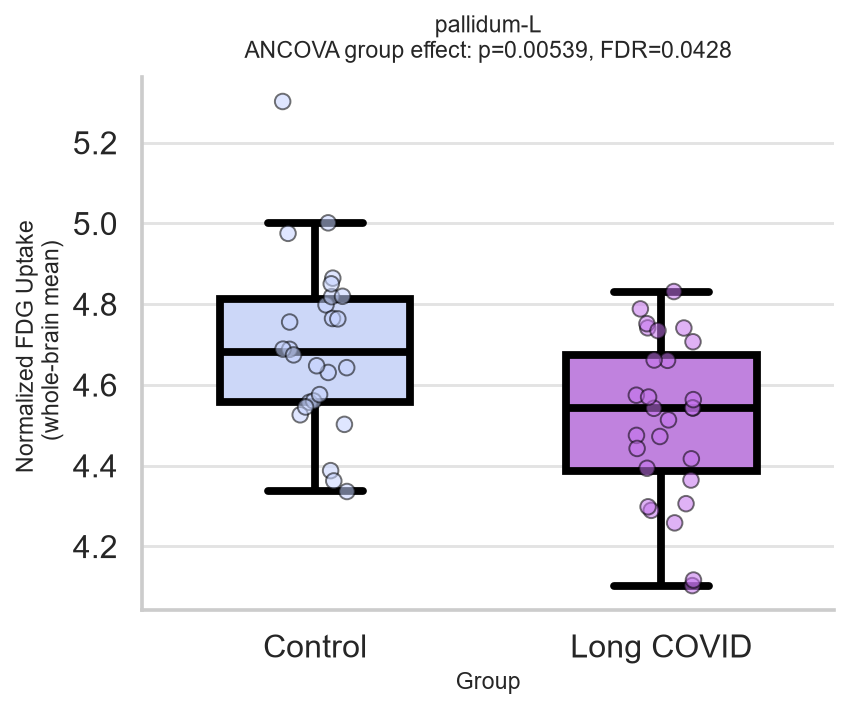

C:\Users\mabel\AppData\Local\Temp\ipykernel_68632\1898926724.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


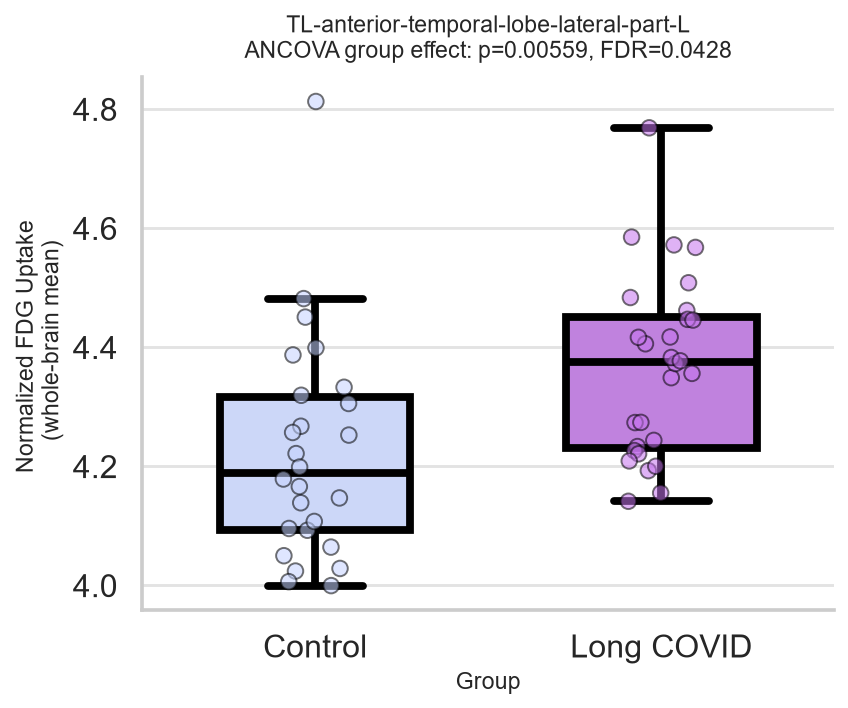

Saved 12 publication-style plots to: ../../../../results/pet/paper_analysis/ancova_rois_mean/plots\ancova_significant_rois


In [ ]:
plots_dir = os.path.join(output_path, "plots", "ancova_significant_rois")
os.makedirs(plots_dir, exist_ok=True)



def clean_filename(name: str) -> str:

    return re.sub(r"[^A-Za-z0-9_.-]+", "_", name)





compare_df["group"] = compare_df["group"].replace(
    {"Controls": "Control", "LC": "Long COVID"}
)

palette = {"Control": "#C5D3FF", "Long COVID": "#C573ED"}

if signif_df.empty:

    print("No significant ROIs after FDR correction. No plots generated.")

else:

    for _, row in signif_df.iterrows():

        roi = row["ROI"]

        sub = compare_df[["group", roi]].dropna().copy()



        fig, ax = plt.subplots(figsize=(6.4, 5.4), dpi=140)



        sns.boxplot(

            data=sub,

            x="group",

            y=roi,

            hue="group",

            order=["Control", "Long COVID"],

            hue_order=["Control", "Long COVID"],

            palette=palette,

            width=0.55,

            fliersize=0,

            linewidth=4,

            linecolor="black",

            dodge=False,

            legend=False,

            ax=ax,

        )



        sns.stripplot(

            data=sub,

            x="group",

            y=roi,

            order=["Control", "Long COVID"],

            hue_order=["Control", "Long COVID"],

            palette=palette,

            #color="#1A1A1A",
            
            edgecolor='black', linewidth=1,


            alpha=0.55,

            size=8,

            jitter=True,

            ax=ax,

        )



        ax.set_xlabel("Group", fontsize=12)

        ax.set_ylabel("Normalized FDG Uptake \n (whole-brain mean)", fontsize=12)

        ax.set_title(

            f"{roi}\nANCOVA group effect: p={row['p_group']:.3g}, FDR={row['p_fdr']:.3g}",

            fontsize=12,

            pad=10,

        )

        ax.spines["top"].set_visible(False)

        ax.spines["right"].set_visible(False)

        ax.grid(axis="y", alpha=0.55)



        plt.tight_layout()

        out_path = os.path.join(plots_dir, f"ancova_ceunim_vs_control_{clean_filename(roi)}.png")

        fig.savefig(out_path, dpi=300, bbox_inches="tight")

        plt.show()

        plt.close(fig)



    print(f"Saved {len(signif_df)} publication-style plots to: {plots_dir}")


In [ ]:
# CEUNIM LC vs CERMEP Control
# For CERMEP we don't have the scan time, so we cannot include it as a covariate
# read df again:
# Load daata from the merged CSV file
df = pd.read_csv(filename_suvr_mean_harmonized)
compare_df = df.loc[
    (df["site"].eq("CEUNIM") & df["group"].eq("LC")) | (df["site"].eq("CERMEP") & df["group"].eq("Controls"))
].copy()

compare_df["sex"] = compare_df["sex"].astype("category")
compare_df["age"] = pd.to_numeric(compare_df["age"], errors="coerce")

excluded = {"ID", "group", "site", "sex", "age", "weight", "analysis_group"}
candidate_roi_cols = [c for c in compare_df.columns if c not in excluded]

roi_cols = []
for col in candidate_roi_cols:
    converted = pd.to_numeric(compare_df[col], errors="coerce")
    if converted.notna().sum() > 0:
        compare_df[col] = converted
        roi_cols.append(col)

print("N subjects for ANCOVA:")
print(compare_df["group"].value_counts(dropna=False))
print(f"Detected ROI SUVR columns: {len(roi_cols)}")

records = []

for roi in roi_cols:
    sub = compare_df[["group", "sex", "age", roi]].dropna().copy()

    if sub["group"].nunique() < 2:
        continue
    if sub["sex"].nunique() < 2:
        continue

    formula = f'Q("{roi}") ~ C(group) + C(sex) + age'
    model = ols(formula, data=sub).fit()
    anova_tbl = sm.stats.anova_lm(model, typ=2)

    group_term = "C(group)"
    if group_term not in anova_tbl.index:
        continue

    mean_control = sub.loc[sub["group"].eq("Controls"), roi].mean()
    mean_lc = sub.loc[sub["group"].eq("LC"), roi].mean()

    records.append(
        {
            "ROI": roi,
            "n": len(sub),
            "F_group": anova_tbl.loc[group_term, "F"],
            "p_group": anova_tbl.loc[group_term, "PR(>F)"],
            "beta_group": model.params.get("C(group)[T.LC]", np.nan),
            "mean_control": mean_control,
            "mean_lc": mean_lc,
            "delta_lc_minus_control": mean_lc - mean_control, 
            "direction": "hyper" if mean_lc > mean_control else "hypo",
            "p_sex": anova_tbl.loc["C(sex)", "PR(>F)"],
            "beta_sex": model.params.get("C(sex)[T.1]", np.nan),
            "p_age": anova_tbl.loc["age", "PR(>F)"],
            "beta_age": model.params.get("age", np.nan)
        }
    )

results_df = pd.DataFrame(records).sort_values("p_group").reset_index(drop=True)
print(results_df)
if len(results_df) > 0:
    rej, p_fdr, _, _ = multipletests(results_df["p_group"], alpha=0.05, method="fdr_bh")
    results_df["p_fdr"] = p_fdr
    results_df["significant_fdr"] = rej
else:
    results_df["p_fdr"] = pd.Series(dtype=float)
    results_df["significant_fdr"] = pd.Series(dtype=bool)

results_df.head(20)

output_filename_csv = os.path.join(output_path, "ancova_lc_vs_cermep_controls_results.csv")
results_df.to_csv(output_filename_csv, index=False)

signif_df = results_df.loc[results_df["significant_fdr"].eq(True)].copy()
signif_df.to_csv(os.path.join(output_path, "ancova_lc_vs_cermep_controls_significant_results_cerebellum.csv"), index=False)
print(f"Saved full ANCOVA table: {output_filename_csv}")
print(f"Significant ROIs (FDR < 0.05): {len(signif_df)}")

N subjects for ANCOVA:
group
Controls    37
LC          28
Name: count, dtype: int64
Detected ROI SUVR columns: 92
                                            ROI   n    F_group       p_group  \
0                      PL-supramarginal-gyrus-L  65  37.329351  7.636622e-08   
1                    FL-lateral-orbital-gyrus-L  65  35.133369  1.547782e-07   
2                     FL-middle-frontal-gyrus-L  65  31.396695  5.362937e-07   
3                  TL-posterior-temporal-lobe-L  65  31.087577  5.957942e-07   
4       TL-middle-and-inferior-temporal-gyrus-L  65  27.908724  1.798373e-06   
..                                          ...  ..        ...           ...   
87                          TL-fusiform-gyrus-L  65   0.005898  9.390368e-01   
88       TL-parahippocampal-and-ambient-gyrus-R  65   0.005590  9.406456e-01   
89      TL-anterior-temporal-lobe-medial-part-L  65   0.003447  9.533731e-01   
90     TL-anterior-temporal-lobe-lateral-part-R  65   0.003435  9.534578e-01   
91  L

In [ ]:
# CEUNIM LC vs All Controls
compare_df = df.loc[
    (df["site"].eq("CEUNIM") & df["group"].eq("LC")) | (df["group"].eq("Controls"))
].copy()

compare_df["sex"] = compare_df["sex"].astype("category")
compare_df["age"] = pd.to_numeric(compare_df["age"], errors="coerce")

excluded = {"ID", "group", "site", "sex", "age", "weight", "analysis_group"}
candidate_roi_cols = [c for c in compare_df.columns if c not in excluded]

roi_cols = []
for col in candidate_roi_cols:
    converted = pd.to_numeric(compare_df[col], errors="coerce")
    if converted.notna().sum() > 0:
        compare_df[col] = converted
        roi_cols.append(col)

print("N subjects for ANCOVA:")
print(compare_df["group"].value_counts(dropna=False))
print(f"Detected ROI SUVR columns: {len(roi_cols)}")

records = []

for roi in roi_cols:
    sub = compare_df[["group", "sex", "age", roi]].dropna().copy()

    if sub["group"].nunique() < 2:
        continue
    if sub["sex"].nunique() < 2:
        continue

    formula = f'Q("{roi}") ~ C(group) + C(sex) + age'
    model = ols(formula, data=sub).fit()
    anova_tbl = sm.stats.anova_lm(model, typ=2)

    group_term = "C(group)"
    if group_term not in anova_tbl.index:
        continue

    mean_control = sub.loc[sub["group"].eq("Controls"), roi].mean()
    mean_lc = sub.loc[sub["group"].eq("LC"), roi].mean()

    records.append(
        {
            "ROI": roi,
            "n": len(sub),
            "F_group": anova_tbl.loc[group_term, "F"],
            "p_group": anova_tbl.loc[group_term, "PR(>F)"],
            "beta_group": model.params.get("C(group)[T.LC]", np.nan),
            "mean_control": mean_control,
            "mean_lc": mean_lc,
            "delta_lc_minus_control": mean_lc - mean_control, 
            "direction": "hyper" if mean_lc > mean_control else "hypo"
        }
    )

results_df = pd.DataFrame(records).sort_values("p_group").reset_index(drop=True)
print(results_df)
if len(results_df) > 0:
    rej, p_fdr, _, _ = multipletests(results_df["p_group"], alpha=0.05, method="fdr_bh")
    results_df["p_fdr"] = p_fdr
    results_df["significant_fdr"] = rej
else:
    results_df["p_fdr"] = pd.Series(dtype=float)
    results_df["significant_fdr"] = pd.Series(dtype=bool)

results_df.head(20)

output_filename_csv = os.path.join(output_path, "ancova_lc_vs_all_controls_results.csv")
results_df.to_csv(output_filename_csv, index=False)

signif_df = results_df.loc[results_df["significant_fdr"].eq(True)].copy()
signif_df.to_csv(os.path.join(output_path, "ancova_lc_vs_all_controls_significant_results_cerebellum.csv"), index=False)
print(f"Saved full ANCOVA table: {output_filename_csv}")
print(f"Significant ROIs (FDR < 0.05): {len(signif_df)}")

N subjects for ANCOVA:
group
Controls    63
LC          28
Name: count, dtype: int64
Detected ROI SUVR columns: 92
                                        ROI   n    F_group       p_group  \
0                  PL-supramarginal-gyrus-L  91  33.321496  1.180219e-07   
1             CG-anterior-cingulate-gyrus-R  91  28.947482  6.199548e-07   
2              TL-posterior-temporal-lobe-L  91  28.882503  6.357524e-07   
3   TL-middle-and-inferior-temporal-gyrus-L  91  28.263400  8.086336e-07   
4                 FL-middle-frontal-gyrus-L  91  24.789156  3.206101e-06   
..                                      ...  ..        ...           ...   
87   TL-parahippocampal-and-ambient-gyrus-L  91   0.007303  9.320944e-01   
88    OL-lateral-remainder-occipital-lobe-L  91   0.001802  9.662355e-01   
89             PL-superior-parietal-gyrus-R  91   0.001771  9.665330e-01   
90            insula-posterior-long-gyrus-L  91   0.000202  9.886885e-01   
91                         TL-hippocampus-L  91  